# K01 — Paleo-prospectivity of porphyry Cu-Au in the SW-Pacific arc system


**Cluster K: Mineral exploration.**
**The region and question follow Farahbakhsh et al. (2025). Reconstruct the dated porphyry copper deposits of New Guinea and the Solomon Islands in the USGS global database (Singer et al., 2008) to their mineralisation ages, overlay the contemporaneous Zahirovic 2022 subduction geometry, and render the result as a paleogeographic map that shows where in the deep past the SW-Pacific arc system was generating economic mineralisation.**

## What this notebook produces

Porphyry Cu-Au deposits form above active subduction zones in distinctive arc-tectonic settings. Their present-day distribution mostly reflects the *cumulative* arc history, not the configuration at any one age — a deposit visible in PNG today may have been generated above a subduction zone that no longer exists, beneath a microcontinent that has since accreted.

This notebook reconstructs the 22 Cenozoic porphyry copper deposits of New Guinea and the Solomon Islands in the USGS database, from Ok Tedi and Grasberg to Panguna, each to its own mineralisation age (1–31 Ma) under Zahirovic 2022 and renders the result on top of the contemporaneous topology. The figure makes the alignment between deposit location and active subduction zone explicit in paleo-coordinates — the basic visual prerequisite for any reconstruction-driven prospectivity study.

A second cell extends the analysis with the simplest possible prospectivity score: distance from each deposit's reconstructed paleo-position to the nearest contemporaneous subduction trench. The histogram of these distances bounds the "porphyry-generating" distance window for the SW-Pacific arc.

**Audience**: postgrad.
**Difficulty**: ★★★.

## Learning objectives

- Reconstruct a set of ore-deposit locations to age-of-mineralisation paleo-positions with `gplately`.
- Overlay reconstructed deposits on contemporaneous subduction-zone geometry from a topological plate model.
- Compute a deposit-to-trench distance metric in paleo-coordinates as a first-order prospectivity score.

## Prerequisites and runtime

- Plate model: Zahirovic 2022.
- Bundled data: `data/porphyry_cu_global/global_porphyry_cu.csv` — the USGS global porphyry copper database (Singer et al., 2008), shared with K02; this notebook keeps the Cenozoic deposits inside `REGION`.
- Python: `gplately`, `pygmt`, `pygplates`, `pandas`, `numpy`.
- Runtime: \~1 minute.


## Data availability

This notebook reads `data/porphyry_cu_global/global_porphyry_cu.csv`, the dated deposits of the USGS database *Porphyry copper deposits of the world* (Singer et al., 2008; U.S. Geological Survey Open-File Report 2008-1155, public domain, `https://pubs.usgs.gov/of/2008/1155/`), and keeps the 22 Cenozoic deposits inside `REGION` (15 in Papua New Guinea, 5 in the Solomon Islands, 2 in Indonesian New Guinea). The same file drives the global analysis in K02; `data/porphyry_cu_global/README.md` describes its columns.

Farahbakhsh et al. (2025) built a spatio-temporal machine-learning prospectivity model for porphyry systems in this region; their notebook is at `https://github.com/EarthByte/STAMP_PNG`.

In [1]:
# Defensive cwd fix: when Jupyter runs this notebook from Notebooks/, the
# `data/...` relative paths used below would not resolve. Step up to the
# suite root once so every `data/...` literal in the rest of the notebook
# finds its file. Idempotent — only runs if `../data` exists and `./data`
# doesn't.
import os as _os
from pathlib import Path as _Path
if _Path("../data").exists() and not _Path("data").exists():
    _os.chdir("..")

# Cell 1 — imports
import os, numpy as np, pandas as pd
import gplately, pygmt, pygplates
from plate_model_manager import PlateModelManager
import sys as _sys
from pathlib import Path as _P
for _d in (_P("Notebooks"), _P("."), _P("../Notebooks")):
    if (_d / "pmm_local.py").exists():
        _sys.path.insert(0, str(_d.resolve())); break
from pmm_local import LocalFirstPMM   # uses the local cache if the model server is unreachable
from IPython.display import display, HTML
# Library versions (printed for reproducibility)
try:
    import gplately, pygmt, pygplates
    print(f"gplately {gplately.__version__}  pygmt {pygmt.__version__}  pygplates {pygplates.__version__}")
except Exception as _e:
    print(f"version probe failed: {_e}")


gplately 2.0.0  pygmt v0.19.0  pygplates 1.0.0


## Configuration

In [2]:
# === USER CONFIGURATION =====================================================
MODEL_NAME    = "Zahirovic2022"
DEPOSITS_CSV  = "data/porphyry_cu_global/global_porphyry_cu.csv"
TARGET_TIME   = 10.0   # Ma — common Miocene snapshot for SW-Pacific porphyries
REGION        = [125, 165, -20, 5]   # (W, E, S, N) — New Guinea + Solomons
AGE_MAX_MA    = 66.0   # Cenozoic arc deposits only; the box also holds Mt Turner (310 Ma, Australian craton)
# ============================================================================


## 1. Load the deposit compilation

In [3]:
# Cell 2 — load, keeping the Cenozoic deposits inside REGION
dep = pd.read_csv(DEPOSITS_CSV, comment="#")
_w, _e, _s, _n = REGION
dep = dep[dep["lon"].between(_w, _e) & dep["lat"].between(_s, _n)
          & (dep["age_ma"] <= AGE_MAX_MA)].reset_index(drop=True)
print(f"  {len(dep)} Cenozoic deposits in REGION, ages {dep['age_ma'].min():g}–{dep['age_ma'].max():g} Ma, "
      f"subtypes {dep['commodity'].value_counts().to_dict()}")
dep[["name", "country", "lon", "lat", "age_ma", "commodity", "tonnage_mt"]].head()

  22 Cenozoic deposits in REGION, ages 1.15–31.3 Ma, subtypes {'Cu': 13, 'Cu-Au': 9}


,name,country,lon,lat,age_ma,commodity,tonnage_mt
0,Ok Tedi,Papua New Guinea,141.13333,-5.20000,1.15,Cu-Au,854.0
1,Koloula,Solomon Islands,160.03333,-9.78333,2.00,Cu,50.0
2,Hidden Valley,Solomon Islands,159.73333,-9.36667,2.60,Cu,NaN
3,Grasberg,Indonesia,137.23333,-3.81667,3.00,Cu-Au,4000.0
4,Panguna,Papua New Guinea,155.50000,-6.31667,3.40,Cu-Au,1420.0


## 2. Reconstruct each deposit to its own mineralisation age

In [4]:
# Cell 3 — per-deposit paleo-positions
pmm   = LocalFirstPMM()
model = pmm.get_model(MODEL_NAME, data_dir="./gplately_data")
recon = gplately.PlateReconstruction(
    rotation_model=model.get_rotation_model(),
    topology_features=model.get_topologies(),
    static_polygons=model.get_static_polygons(),
)

paleo_lons, paleo_lats = [], []
for _, row in dep.iterrows():
    pt = gplately.Points(recon, [row["lon"]], [row["lat"]])
    rlon, rlat = pt.reconstruct(float(row["age_ma"]), return_array=True)
    paleo_lons.append(float(rlon[0])); paleo_lats.append(float(rlat[0]))
dep["paleo_lon"] = paleo_lons
dep["paleo_lat"] = paleo_lats


## 3. Paleogeographic map at TARGET_TIME with deposits coloured by age


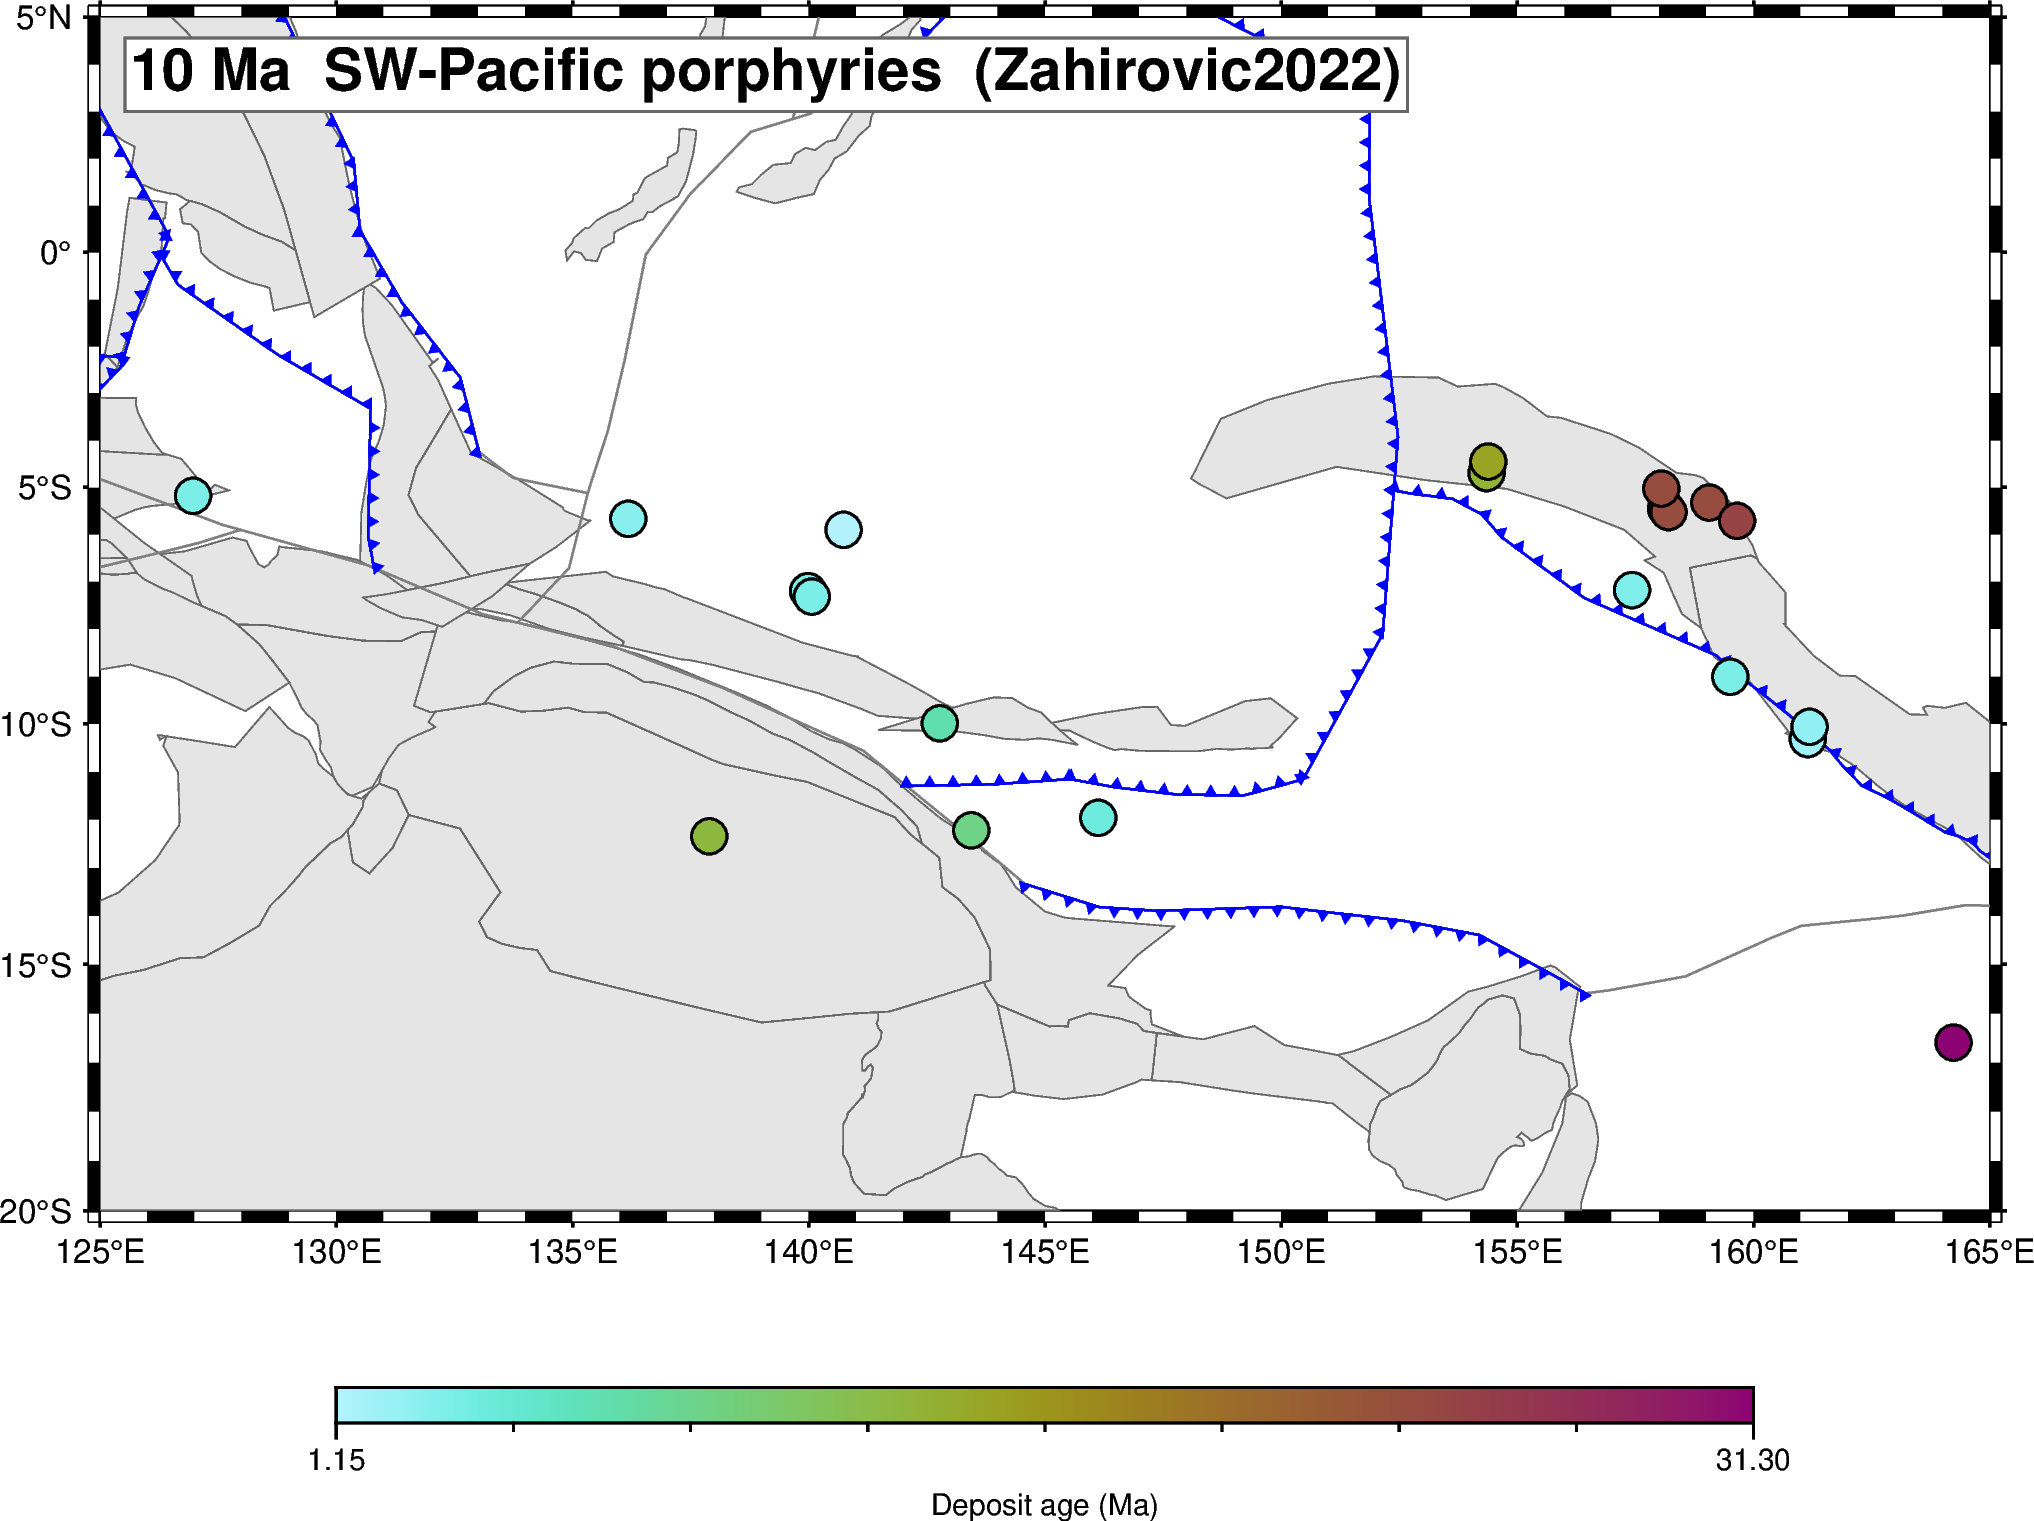

In [5]:
# Cell 4 — render
gplot = gplately.PlotTopologies(
    plate_reconstruction=recon,
    coastlines=model.get_coastlines(),
    continents=model.get_continental_polygons(),
    COBs=model.get_COBs(),
    time=float(TARGET_TIME),
    plot_engine=gplately.PygmtPlotEngine(),
    )

fig = pygmt.Figure()
fig.basemap(region=REGION, projection="M16c", frame=["af"])
gplot.plot_continents(fig, fill="gray90", pen="0.3p,gray40")
gplot.plot_all_topological_sections(fig, pen="0.5p,gray50")
(_tl, _tr) = gplot.get_subduction_direction()
gplot.plot_subduction_teeth(fig, color="blue")

# Colour scale: series=[min, max, 1] previously forced the CPT into
# fixed 1-Myr bins that, whenever (max - min) isn't a whole multiple of
# 1, silently truncate the top of the range short of the true max age
# — and the default "af" colorbar frame anchors its annotated ticks to
# round multiples of the annotation interval starting from zero, which
# generally do NOT land on the actual (non-round) min/max ages. Net
# effect: a reader can't tell what the true minimum/maximum deposit
# age is from the colorbar. Fix: build the CPT directly from the exact
# data range (no fixed step, so GMT resamples "hawaii" smoothly across
# the full min-max span with no truncation), add background=True so
# any point exactly at the extremes still maps to the cmap's own end
# colours rather than the gmt.conf background/foreground defaults, and
# phase-shift the colorbar's annotation stride (stride = full age
# span, phase = AGE_MIN) so GMT's major annotated ticks land exactly
# on AGE_MIN and AGE_MAX — both ends of the bar are now explicitly
# labeled with the real data extremes.
AGE_MIN = float(dep["age_ma"].min())
AGE_MAX = float(dep["age_ma"].max())
_age_span = AGE_MAX - AGE_MIN
pygmt.makecpt(cmap="hawaii", series=[AGE_MIN, AGE_MAX], reverse=True,
              background=True)
fig.plot(x=dep["paleo_lon"], y=dep["paleo_lat"],
         style="c0.30c", fill=dep["age_ma"], cmap=True,
         pen="0.6p,black")
fig.colorbar(
    frame=[f"xa{_age_span:.6g}+{AGE_MIN:.6g}f{max(_age_span / 8, 1e-6):.6g}"
           "+lDeposit age (Ma)"],
    position="JBC+w12c/0.3c+h+o0/1.5c")
fig.text(text=f"{TARGET_TIME:.0f} Ma  SW-Pacific porphyries  ({MODEL_NAME})",
         position="TL", offset="0.25c/-0.25c", justify="TL",
         font="14p,Helvetica-Bold,black",
         fill="white", pen="0.6p,gray40")
fig.show(width=1100)
display(HTML('<div style="height:1cm"></div>'))


## 4. Deposit-to-trench distance — first-order prospectivity score

In [6]:
# Cell 5 — distance to nearest trench
def trench_distance_km(plon, plat, t):
    """Great-circle distance from (plon, plat) to the nearest contemporaneous
    subduction-zone segment in km."""
    gplot.time = float(t)
    trenches = gplot.get_trenches()
    if trenches is None or len(trenches) == 0:
        return np.nan
    pt = pygplates.PointOnSphere(plat, plon)
    best = np.inf
    for geom in trenches.geometry:
        if geom is None: continue
        parts = geom.geoms if hasattr(geom, "geoms") else [geom]
        for part in parts:
            for x, y in part.coords:
                d = pygplates.GeometryOnSphere.distance(
                    pt, pygplates.PointOnSphere(y, x)) * 6371.0
                if d < best: best = d
    return best

dep["trench_dist_km"] = [
    trench_distance_km(row["paleo_lon"], row["paleo_lat"], row["age_ma"])
    for _, row in dep.iterrows()
]
print(f"  median deposit-to-trench distance: {dep['trench_dist_km'].median():.0f} km")
print(f"  90 %-ile: {dep['trench_dist_km'].quantile(0.9):.0f} km")


  median deposit-to-trench distance: 179 km
  90 %-ile: 319 km


## Extend this

- **Spatio-temporal ML.** This notebook computes one prospectivity feature (deposit-to-trench distance). Farahbakhsh et al. (2025) train a classifier on a feature stack including convergence rate, slab dip, sediment thickness, and subduction obliquity. Their workflow is in the `STAMP_PNG` repository.
- **Subtype.** Filter to `commodity == "Cu-Au"` or `commodity == "Cu"` and re-run, then compare the deposit-to-trench distances of the two subtypes.
- **Wider region.** Extend `REGION` west to include the Philippines and Indonesia, which the USGS database also covers.
- **Cross-reference B06.** B06 maps paleo-σHmax along subduction zones; K01 maps paleo-deposits along subduction zones. Overlay both for a single age and look for systematic alignment between σHmax orientation and the porphyry-generating front.

## References

- Farahbakhsh, E., Zahirovic, S., McInnes, B.I.A., Polanco, S., Kohlmann, F., Seton, M. & Müller, R.D. (2025). Machine learning-based spatio-temporal prospectivity modeling of porphyry systems in the New Guinea and Solomon Islands region. *Tectonics* 44(3), e2024TC008362. https://doi.org/10.1029/2024TC008362
- Singer, D.A., Berger, V.I. & Moring, B.C. (2008). Porphyry copper deposits of the world: database and grade and tonnage models, 2008. *U.S. Geological Survey Open-File Report* 2008-1155. https://pubs.usgs.gov/of/2008/1155/
- Zahirovic, S., Eleish, A., Doss, S., Pall, J., Cannon, J., Pistone, M., Tetley, M.G., Young, A. & Fox, P. (2022). Subduction and carbonate platform interactions. *Geoscience Data Journal* 9(2), 371-383. https://doi.org/10.1002/gdj3.146
- Mather, B.R., Müller, R.D., Zahirovic, S., Cannon, J., Chin, M., Ilano, L., Wright, N.M., Alfonso, C., Williams, S., Tetley, M. & Merdith, A. (2024). Deep time spatio-temporal data analysis using pyGPlates with PlateTectonicTools and GPlately. *Geoscience Data Journal* 11(1), 3–10. https://doi.org/10.1002/gdj3.185
- Tian, D., Uieda, L., Leong, W.J., Fröhlich, Y., Schlitzer, W., Grund, M., Jones, M., Toney, L., Yao, J., Magen, Y., Tong, J.-H., Ngo, L., Materna, K., Belem, A., Newton, T., Anant, A., Ziebarth, M., Quinn, J. & Wessel, P. (2024). PyGMT: A Python interface for the Generic Mapping Tools. *Zenodo*. https://doi.org/10.5281/zenodo.13679420
- Wessel, P., Luis, J.F., Uieda, L., Scharroo, R., Wobbe, F., Smith, W.H.F. & Tian, D. (2019). The Generic Mapping Tools version 6. *Geochemistry, Geophysics, Geosystems* 20(11), 5556–5564. https://doi.org/10.1029/2019GC008515

- Butterworth, N., Steinberg, D., Müller, R.D., Williams, S., Merdith, A.S. & Hardy, S. (2016). Tectonic environments of South American porphyry copper magmatism through time revealed by spatiotemporal data mining. *Tectonics* 35(12), 2847-2862. https://doi.org/10.1002/2016TC004289
- Sillitoe, R.H. (2010). Porphyry copper systems. *Economic Geology* 105(1), 3–41. https://doi.org/10.2113/gsecongeo.105.1.3
